In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("retail_sales_dataset.csv")
print(df.shape)
df.info()
print(df.isnull().sum())
df.head()

(1000, 9)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   Transaction ID    1000 non-null   int64 
 1   Date              1000 non-null   object
 2   Customer ID       1000 non-null   object
 3   Gender            1000 non-null   object
 4   Age               1000 non-null   int64 
 5   Product Category  1000 non-null   object
 6   Quantity          1000 non-null   int64 
 7   Price per Unit    1000 non-null   int64 
 8   Total Amount      1000 non-null   int64 
dtypes: int64(5), object(4)
memory usage: 70.4+ KB
Transaction ID      0
Date                0
Customer ID         0
Gender              0
Age                 0
Product Category    0
Quantity            0
Price per Unit      0
Total Amount        0
dtype: int64


,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100


## Initial Data Inspection

**Observations:**
- The dataset contains **1,000 rows and 9 columns** (Transaction ID, Date, Customer ID, Gender, Age, Product Category, Quantity, Price per Unit, Total Amount).
- There are **no null values** in any column, so no imputation was needed.
- There are **no duplicate rows**.
- The `Date` column was stored as text (object), so I converted it to **datetime** to enable time-series analysis.
- The data covers **1 January 2023 to 1 January 2024**, i.e. one full year of transactions.

In [2]:
df['Date'] = pd.to_datetime(df['Date'])
print(df.dtypes)
print("Duplicates:", df.duplicated().sum())
print("Date range:", df['Date'].min(), "to", df['Date'].max())

Transaction ID               int64
Date                datetime64[ns]
Customer ID                 object
Gender                      object
Age                          int64
Product Category            object
Quantity                     int64
Price per Unit               int64
Total Amount                 int64
dtype: object
Duplicates: 0
Date range: 2023-01-01 00:00:00 to 2024-01-01 00:00:00


## Descriptive Statistics

**Observations:**
- **Age:** mean (41.4), median (42) and mode (43) are very close, so ages are fairly evenly spread. Customers range from 18 to 64 years, with a standard deviation of about 13.7.
- **Quantity:** customers buy between 1 and 4 units per transaction (mean 2.5, median 3, mode 4).
- **Price per Unit:** the mean (179.89) is much higher than the median (50), which shows the data is **right-skewed**: most items are low-priced, while a smaller number of expensive items (up to 500) pull the average up. The high standard deviation (189.7) supports this.
- **Total Amount:** mean (456) is far above the median (135), and the maximum is 2,000, so this column is also **right-skewed**. A few high-value transactions contribute a large share of revenue.
- Overall, there are no impossible values (no negatives or zeros), so the dataset looks clean and consistent.

In [3]:
num_cols = ['Age', 'Quantity', 'Price per Unit', 'Total Amount']

stats = pd.DataFrame({
    'Mean': df[num_cols].mean(),
    'Median': df[num_cols].median(),
    'Mode': df[num_cols].mode().iloc[0],
    'Std Dev': df[num_cols].std()
})
print(stats.round(2))
df[num_cols].describe()

                  Mean  Median  Mode  Std Dev
Age              41.39    42.0  43.0    13.68
Quantity          2.51     3.0   4.0     1.13
Price per Unit  179.89    50.0  50.0   189.68
Total Amount    456.00   135.0  50.0   560.00


,Age,Quantity,Price per Unit,Total Amount
count,1000.00000,1000.000000,1000.000000,1000.000000
mean,41.39200,2.514000,179.890000,456.000000
std,13.68143,1.132734,189.681356,559.997632
min,18.00000,1.000000,25.000000,25.000000
25%,29.00000,1.000000,30.000000,60.000000
50%,42.00000,3.000000,50.000000,135.000000
75%,53.00000,4.000000,300.000000,900.000000
max,64.00000,4.000000,500.000000,2000.000000


## Time Series Analysis

Note: The dataset contains only one transaction day in January 2024 (1 Jan), so it was excluded from the monthly/quarterly trend to avoid a misleading partial period. The trend below covers the full year 2023.

Monthly Sales:
 Date
2023-01    35450
2023-02    44060
2023-03    28990
2023-04    33870
2023-05    53150
2023-06    36715
2023-07    35465
2023-08    36960
2023-09    23620
2023-10    46580
2023-11    34920
2023-12    44690
Freq: M, Name: Total Amount, dtype: int64 

Quarterly Sales:
 Date
2023Q1    108500
2023Q2    123735
2023Q3     96045
2023Q4    126190
Freq: Q-DEC, Name: Total Amount, dtype: int64


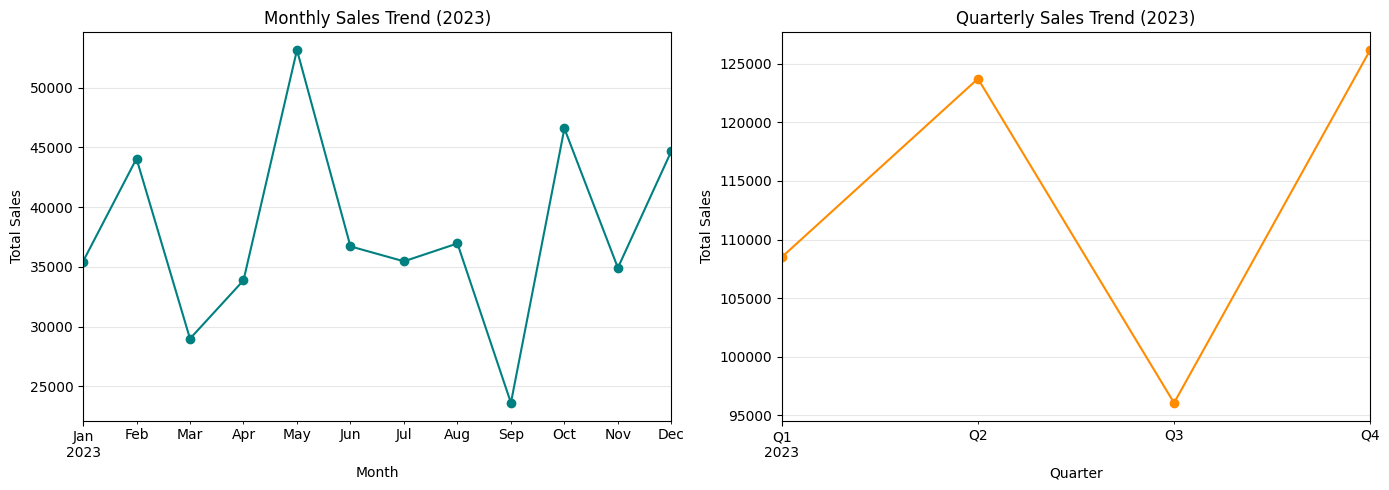

In [4]:
# 1 Jan 2024 sirf ek din hai, isliye time series ke liye sirf 2023 use kar rahe hain
ts = df[df['Date'] < '2024-01-01'].copy()

monthly = ts.groupby(ts['Date'].dt.to_period('M'))['Total Amount'].sum()
quarterly = ts.groupby(ts['Date'].dt.to_period('Q'))['Total Amount'].sum()

print("Monthly Sales:\n", monthly, "\n")
print("Quarterly Sales:\n", quarterly)

fig, ax = plt.subplots(1, 2, figsize=(14, 5))

monthly.plot(ax=ax[0], marker='o', color='teal')
ax[0].set_title('Monthly Sales Trend (2023)')
ax[0].set_xlabel('Month')
ax[0].set_ylabel('Total Sales')
ax[0].grid(alpha=0.3)

quarterly.plot(ax=ax[1], marker='o', color='darkorange')
ax[1].set_title('Quarterly Sales Trend (2023)')
ax[1].set_xlabel('Quarter')
ax[1].set_ylabel('Total Sales')
ax[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

### Observations: Sales Trends (2023)

- **Monthly:** Sales fluctuate a lot from month to month rather than following a steady upward or downward trend. The **peak was May (53,150)** and the **lowest was September (23,620)**, so May's sales were more than double September's.
- **Sharp swings:** There was a big drop from May to the following months, and a very sharp recovery from September (23,620) to October (46,580), almost doubling in one month. Other dips were in March (28,990) and November (34,920).
- **Quarterly:** Q4 was the strongest quarter (126,190), closely followed by Q2 (123,735). **Q3 was the weakest (96,045)**, about 22% lower than Q2. Sales then recovered by about 31% from Q3 to Q4.
- Total sales for 2023 were about 454,470, and Q4 alone contributed roughly 28% of it.
- Since the dataset covers only one year, I cannot confirm whether these patterns are true seasonality (for example, year-end shopping) or just random variation. This would need multiple years of data.

## Customer Demographics Analysis

Age Group
18-24    149
25-34    203
35-44    207
45-54    225
55-64    216
Name: count, dtype: int64 

Gender
Female    510
Male      490
Name: count, dtype: int64 

Gender
Female    232840
Male      223160
Name: Total Amount, dtype: int64


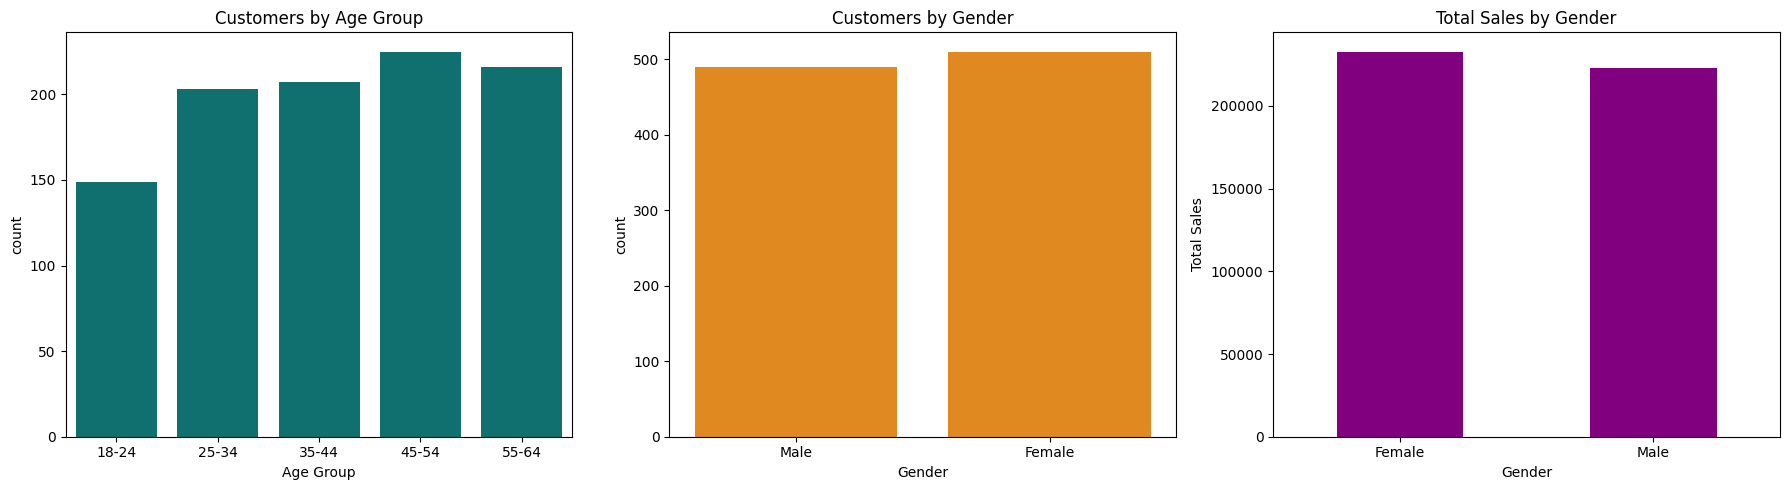

In [5]:
bins = [17, 24, 34, 44, 54, 64]
labels = ['18-24', '25-34', '35-44', '45-54', '55-64']
df['Age Group'] = pd.cut(df['Age'], bins=bins, labels=labels)

print(df['Age Group'].value_counts().sort_index(), "\n")
print(df['Gender'].value_counts(), "\n")
print(df.groupby('Gender')['Total Amount'].sum())

fig, ax = plt.subplots(1, 3, figsize=(18, 5))

sns.countplot(x='Age Group', data=df, color='teal', ax=ax[0])
ax[0].set_title('Customers by Age Group')

sns.countplot(x='Gender', data=df, color='darkorange', ax=ax[1])
ax[1].set_title('Customers by Gender')

df.groupby('Gender')['Total Amount'].sum().plot(kind='bar', color='purple', ax=ax[2])
ax[2].set_title('Total Sales by Gender')
ax[2].set_ylabel('Total Sales')
ax[2].tick_params(axis='x', rotation=0)

plt.tight_layout()
plt.show()

### Observations: Customer Demographics

- **Age groups:** Customers are spread fairly evenly across ages. The **45-54 group is the largest (225 customers, 22.5%)**, followed by 55-64 (216) and 35-44 (207). The **18-24 group is the smallest (149, 14.9%)**, so younger customers are underrepresented compared to the other groups.
- **Gender:** The split is almost equal: **510 female (51%) and 490 male (49%)** customers.
- **Sales by gender:** Female customers generated slightly more revenue (**232,840 vs 223,160**), about 51% of total sales. The gap is mainly because there are slightly more female customers; the average spend per transaction is nearly the same for both (about 456 for females and 455 for males).
- Overall, the customer base is balanced by gender and skews toward adults aged 25 and above, so marketing should not rely on one gender, and there may be an opportunity to attract more customers in the 18-24 group.

## Product Analysis

Note: This dataset has no individual product names, only 3 product categories (Beauty, Clothing, Electronics). Instead of a "top 10 products" list, the categories are ranked by revenue and units sold.

                  Revenue  Units_Sold  Transactions  Avg_Price  \
Product Category                                                 
Electronics        156905         849           342     181.90   
Clothing           155580         894           351     174.29   
Beauty             143515         771           307     184.06   

                  Revenue Share %  
Product Category                   
Electronics                  34.4  
Clothing                     34.1  
Beauty                       31.5  


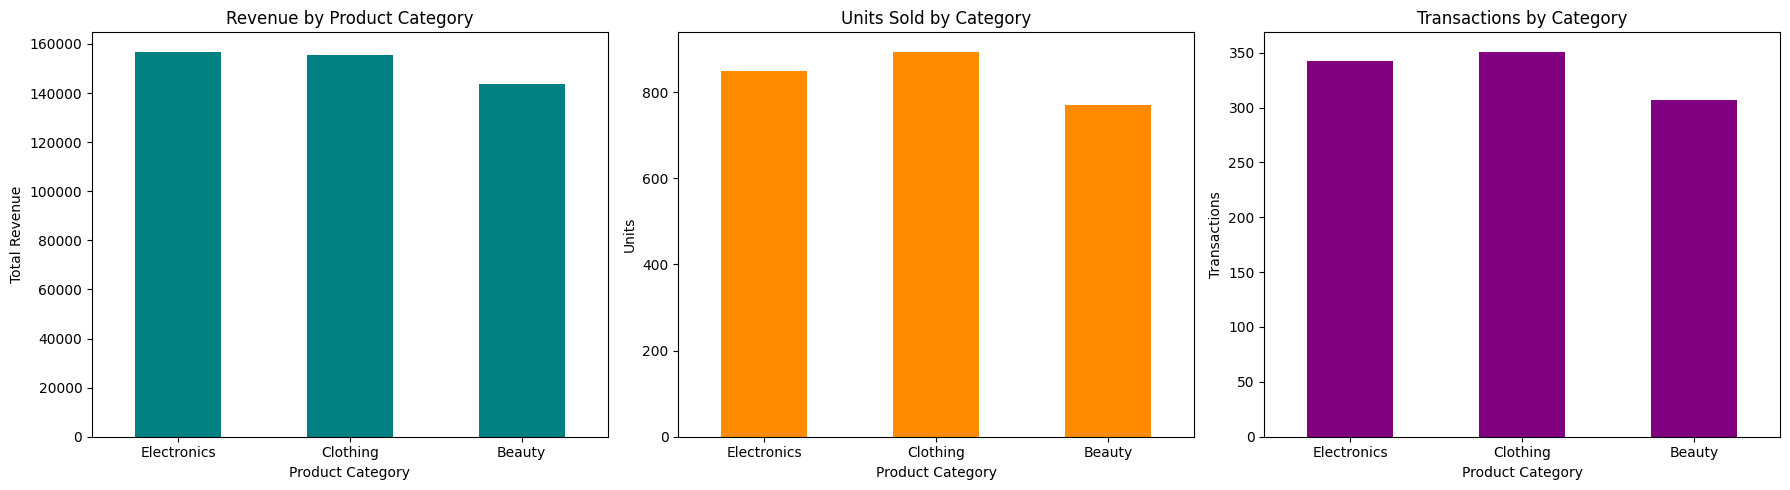

In [6]:
cat = df.groupby('Product Category').agg(
    Revenue=('Total Amount', 'sum'),
    Units_Sold=('Quantity', 'sum'),
    Transactions=('Transaction ID', 'count'),
    Avg_Price=('Price per Unit', 'mean')
).sort_values('Revenue', ascending=False)

cat['Revenue Share %'] = (cat['Revenue'] / cat['Revenue'].sum() * 100).round(1)
print(cat.round(2))

fig, ax = plt.subplots(1, 3, figsize=(18, 5))

cat['Revenue'].plot(kind='bar', color='teal', ax=ax[0])
ax[0].set_title('Revenue by Product Category')
ax[0].set_ylabel('Total Revenue')

cat['Units_Sold'].plot(kind='bar', color='darkorange', ax=ax[1])
ax[1].set_title('Units Sold by Category')
ax[1].set_ylabel('Units')

cat['Transactions'].plot(kind='bar', color='purple', ax=ax[2])
ax[2].set_title('Transactions by Category')
ax[2].set_ylabel('Transactions')

for a in ax:
    a.tick_params(axis='x', rotation=0)

plt.tight_layout()
plt.show()

### Observations: Product Category Analysis

- **Revenue:** The three categories earn almost the same amount. **Electronics leads (156,905, 34.4%)**, followed very closely by **Clothing (155,580, 34.1%)**, while **Beauty is the lowest (143,515, 31.5%)**. The gap between first and last is about 13,400, or roughly 8.5% of Electronics revenue.
- **Volume:** **Clothing sells the most units (894) and has the most transactions (351)**, but it ranks second in revenue. Electronics earns more revenue from fewer units (849), so each Electronics sale is worth slightly more.
- **Beauty:** It has the lowest units (771) and transactions (307), even though its average price per unit (184.06) is the highest of the three. This suggests Beauty is not weak because of pricing, but because fewer customers buy it.
- Overall, no single category dominates; revenue is well balanced across all three. The best opportunity is to increase Beauty purchases, since it has the lowest volume.
- Limitation: the dataset has only 3 categories and no product names, so a product-level "top 10" analysis was not possible.

## Correlation Analysis

                 Age  Quantity  Price per Unit  Total Amount
Age             1.00     -0.02           -0.04         -0.06
Quantity       -0.02      1.00            0.02          0.37
Price per Unit -0.04      0.02            1.00          0.85
Total Amount   -0.06      0.37            0.85          1.00


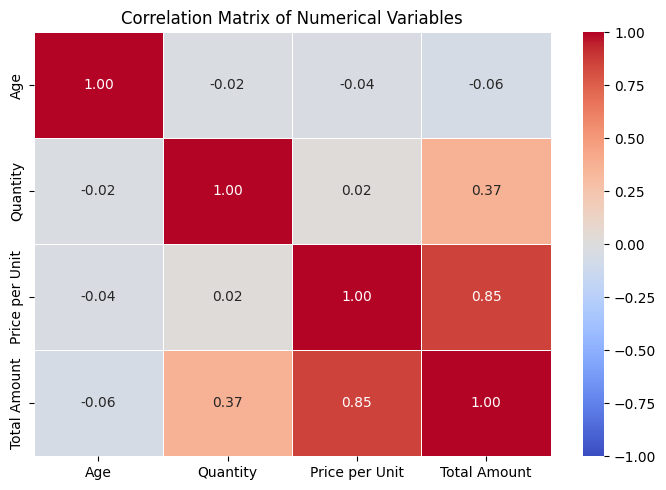

In [7]:
corr_cols = ['Age', 'Quantity', 'Price per Unit', 'Total Amount']
corr = df[corr_cols].corr()
print(corr.round(2))

plt.figure(figsize=(7, 5))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, linewidths=0.5)
plt.title('Correlation Matrix of Numerical Variables')
plt.tight_layout()
plt.show()

### Observations: Correlation Analysis

- **Price per Unit vs Total Amount (0.85):** very strong positive correlation. Transactions with higher-priced items tend to have much higher totals.
- **Quantity vs Total Amount (0.37):** moderate positive correlation. Buying more units raises the total, but less strongly than price does. This is because Price per Unit varies widely (25 to 500), while Quantity only ranges from 1 to 4.
- **Quantity vs Price per Unit (0.02):** almost no relationship, so customers do not buy fewer units when items are expensive, or more units when items are cheap.
- **Age:** its correlation with every other variable is close to zero (between -0.02 and -0.06), so age shows no meaningful linear relationship with quantity, price or spending.
- Note: Total Amount is calculated as Quantity × Price per Unit, so its high correlation with those two columns is expected by construction and is not a new discovery. The more useful finding is that age alone does not predict how much a customer spends. Correlation only measures linear relationships, so other patterns (for example by age group or category) could still exist.

## Additional Visualisation: Revenue by Age Group and Product Category

Product Category  Beauty  Clothing  Electronics
Age Group                                      
18-24              28905     22160        23585
25-34              28540     41640        26910
35-44              29450     30925        36460
45-54              35950     29545        31740
55-64              20670     31310        38210

Average spend per transaction:
 Gender     Female   Male
Age Group               
18-24       498.9  503.0
25-34       508.3  447.9
35-44       472.9  461.8
45-54       407.2  458.3
55-64       415.4  419.7


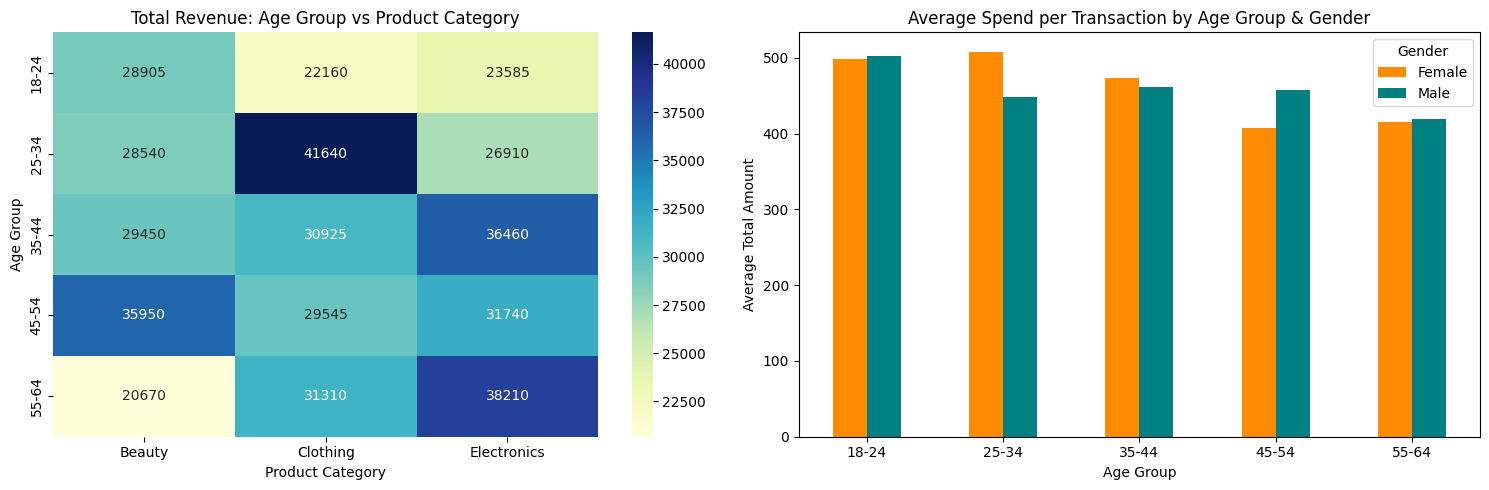

In [8]:
pivot = df.pivot_table(values='Total Amount', index='Age Group',
                       columns='Product Category', aggfunc='sum', observed=True)
print(pivot)

avg_spend = df.pivot_table(values='Total Amount', index='Age Group',
                           columns='Gender', aggfunc='mean', observed=True)
print("\nAverage spend per transaction:\n", avg_spend.round(1))

fig, ax = plt.subplots(1, 2, figsize=(15, 5))

sns.heatmap(pivot, annot=True, fmt='.0f', cmap='YlGnBu', ax=ax[0])
ax[0].set_title('Total Revenue: Age Group vs Product Category')

avg_spend.plot(kind='bar', ax=ax[1], color=['darkorange', 'teal'])
ax[1].set_title('Average Spend per Transaction by Age Group & Gender')
ax[1].set_ylabel('Average Total Amount')
ax[1].tick_params(axis='x', rotation=0)

plt.tight_layout()
plt.show()

### Observations: Age Group vs Product Category

- **Clothing peaks among 25-34 year olds:** this is the highest value in the heatmap (41,640), almost double Clothing revenue from 18-24 (22,160).
- **Electronics grows with age:** revenue rises from 23,585 (18-24) to its highest in the **55-64 group (38,210)**, about 62% more than the youngest group.
- **Beauty is strongest at 45-54 (35,950) and weakest at 55-64 (20,670).**
- So although age has almost no linear correlation with total spending (see correlation matrix), **different age groups clearly prefer different categories**. This is a pattern that the correlation matrix alone could not show.
- **Average spend per transaction:** the youngest group (18-24) spends the most per transaction (about 499 for females and 503 for males) even though it has the fewest customers. In the 25-34 group, females spend more than males (508 vs 448), while in the 45-54 group males spend more (458 vs 407).
- Limitation: with only 1,000 transactions split across 15 age-category cells, each cell has roughly 65 transactions, so some of these differences may be due to chance and should be treated as indications, not proof.

## Conclusion and Business Recommendations

**Summary of findings:** Using one year (2023) of retail data with 1,000 transactions, the business has a balanced customer base (51% female, 49% male), evenly distributed revenue across three categories (Electronics 34.4%, Clothing 34.1%, Beauty 31.5%), and highly uneven monthly sales (peak in May, low in September). Price per unit is the main driver of transaction value, while age shows no linear relationship with spending.

**Recommendations:**
1. **Run targeted category campaigns by age group.** Promote Clothing to customers aged 25-34 and Electronics to customers aged 35 and above (especially 55-64), where these categories already perform best. Use Beauty promotions for the 55-64 group, where Beauty sales are lowest.
2. **Plan for the September / Q3 slump.** September (23,620) was the weakest month and Q3 the weakest quarter (96,045). Offering discounts, bundles or loyalty rewards in this period could help smooth revenue, and extra stock should be prepared for the strong months (May and Q4).
3. **Grow the 18-24 segment.** It is the smallest customer group (149 customers) but has the highest average spend per transaction (about 500). Social media and student-focused offers could attract more of these customers.
4. **Increase Beauty sales.** Beauty has the lowest revenue, units and transactions despite having the highest average price per unit, so cross-selling or bundling it with Clothing or Electronics purchases is worth testing.

**Limitations:** The dataset covers only one year, so seasonality cannot be confirmed. It contains no product names or store locations, so product-level and regional analysis was not possible, and some differences between small groups may be due to chance.